In [ ]:
import os
import certifi
import requests
from dotenv import load_dotenv

from langchain_openai import ChatOpenAI
from langchain.tools import tool
from langchain_community.tools.tavily_search import TavilySearchResults
from langchain import hub




In [ ]:
from langchain.agents import create_react_agent, AgentExecutor

In [36]:
os.environ["SSL_CERT_FILE"] = certifi.where()
load_dotenv()

OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")
TAVILY_API_KEY = os.getenv("TAVILY_API_KEY")
WEATHERSTACK_API_KEY = os.getenv("WEATHERSTACK_API_KEY")

In [4]:
search_tool = TavilySearchResults(max_results=4)

In [37]:
@tool
def get_weather_data(city: str) -> str:
    """
    Fetch current weather information for a city.
    """

    url = (
        f"https://api.weatherstack.com/current?"
        f"access_key={WEATHERSTACK_API_KEY}&query={city}"
    )

    response = requests.get(url)

    data = response.json()

    if "current" not in data:
        return f"Could not fetch weather data for {city}"

    return (
        f"City: {city}\n"
        f"Temperature: {data['current']['temperature']}°C\n"
        f"Weather: {data['current']['weather_descriptions'][0]}\n"
        f"Humidity: {data['current']['humidity']}%"
    )

In [5]:
result = search_tool.invoke("Give me the latest news on ai")
result

[{'url': 'https://www.crescendo.ai/news/latest-ai-news-and-updates',
  'content': "Date: May 21, 2026\n\nSummary: SoundHound AI announced the acquisition of conversational AI platform LivePerson, combining its voice and audio recognition capabilities with LivePerson's digital messaging products. Management has set 2027 revenue targets of $350 million to $400 million and identified a $500 million cross-selling opportunity across the combined customer base. The deal positions SoundHound to compete more directly with Microsoft, Google, and Amazon across enterprise contact centers, healthcare, and financial services.\n\nSource: Simply Wall St ↗\n\n### (AI News) Nvidia's Memory Costs Soar 485% as Latest AI Systems Now Cost $7.8 Million to Build\n\nDate: May 21, 2026 [...] Date: July 2, 2026\n\nSummary: Anthropic is in early discussions with Samsung to develop a custom AI chip, joining competitors seeking to reduce reliance on Nvidia. The move follows OpenAI's announcement of its own custom 

In [ ]:
llm = ChatOpenAI(model="gpt-3.5-turbo", temperature=0)

response = llm.invoke("What is the latest news on ai?")
response


AIMessage(content='One of the latest news on AI is the development of GPT-3 (Generative Pre-trained Transformer 3), a language model created by OpenAI that has 175 billion parameters, making it one of the largest AI models ever created. GPT-3 has shown impressive capabilities in generating human-like text and has been used in various applications such as chatbots, content generation, and language translation. Additionally, there have been advancements in AI ethics and regulation, with governments and organizations around the world working to establish guidelines and frameworks for the responsible development and deployment of AI technologies.', response_metadata={'token_usage': {'completion_tokens': 116, 'prompt_tokens': 15, 'total_tokens': 131, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-3.5-turbo', 'system

In [9]:
prompt = hub.pull("hwchase17/react")
prompt

/opt/homebrew/Caskroom/miniconda/base/envs/langagent/lib/python3.11/site-packages/langchain/hub.py:86: DeprecationWarning: The `langchainhub sdk` is deprecated.
Please use the `langsmith sdk` instead:
  pip install langsmith
Use the `pull_prompt` method.
  res_dict = client.pull_repo(owner_repo_commit)


PromptTemplate(input_variables=['agent_scratchpad', 'input', 'tool_names', 'tools'], metadata={'lc_hub_owner': 'hwchase17', 'lc_hub_repo': 'react', 'lc_hub_commit_hash': 'd15fe3c426f1c4b3f37c9198853e4a86e20c425ca7f4752ec0c9b0e97ca7ea4d'}, template='Answer the following questions as best you can. You have access to the following tools:\n\n{tools}\n\nUse the following format:\n\nQuestion: the input question you must answer\nThought: you should always think about what to do\nAction: the action to take, should be one of [{tool_names}]\nAction Input: the input to the action\nObservation: the result of the action\n... (this Thought/Action/Action Input/Observation can repeat N times)\nThought: I now know the final answer\nFinal Answer: the final answer to the original input question\n\nBegin!\n\nQuestion: {input}\nThought:{agent_scratchpad}')

In [38]:
tools = [search_tool, get_weather_data]
# tools = []

In [19]:
agent = create_react_agent(llm, tools, prompt)

In [20]:
agent_executor = AgentExecutor(agent=agent, tools=tools, verbose=True)

In [39]:
response = agent_executor.invoke({
    "input":( 
        "Find the capital of India"
        "and then find its current weather"
        # "find the latest news on iran and us war"
    )
    })
response



> Entering new AgentExecutor chain...
I should use the search engine to find the capital of India first and then search for its current weather.
Action: tavily_search_results_json
Action Input: "capital of India"[{'url': 'https://www.facebook.com/100091292563264/posts/what-is-the-capital-of-india/858899117163166', 'content': 'Capital of India New Delhi is an urban district of Delhi which serves as the capital of India and seat of all three branches of the Government'}, {'url': 'https://timesofindia.indiatimes.com/india/list-of-cities-that-served-as-the-capital-of-india/articleshow/111815680.cms', 'content': "| Era | Capital(s) | Description |\n| Modern | Allahabad | Capital of India for a day in 1858, capital of North-Western Provinces. |\n| Calcutta | Capital of British India until 1911. |\n| Shimla | Summer capital by the latter half of the 19th century. |\n| New Delhi | Capital of India since 1911, buildings inaugurated in early 1931. |\n| Mediaeval | Agra | Capital of Sikandar Lo

{'input': 'Find the capital of Indiaand then find its current weather',
 'output': 'The capital of India is New Delhi, and the current weather in New Delhi is around 23°C with clear skies, a high of 29°C, and a low of 20°C.'}

thought
action
observation

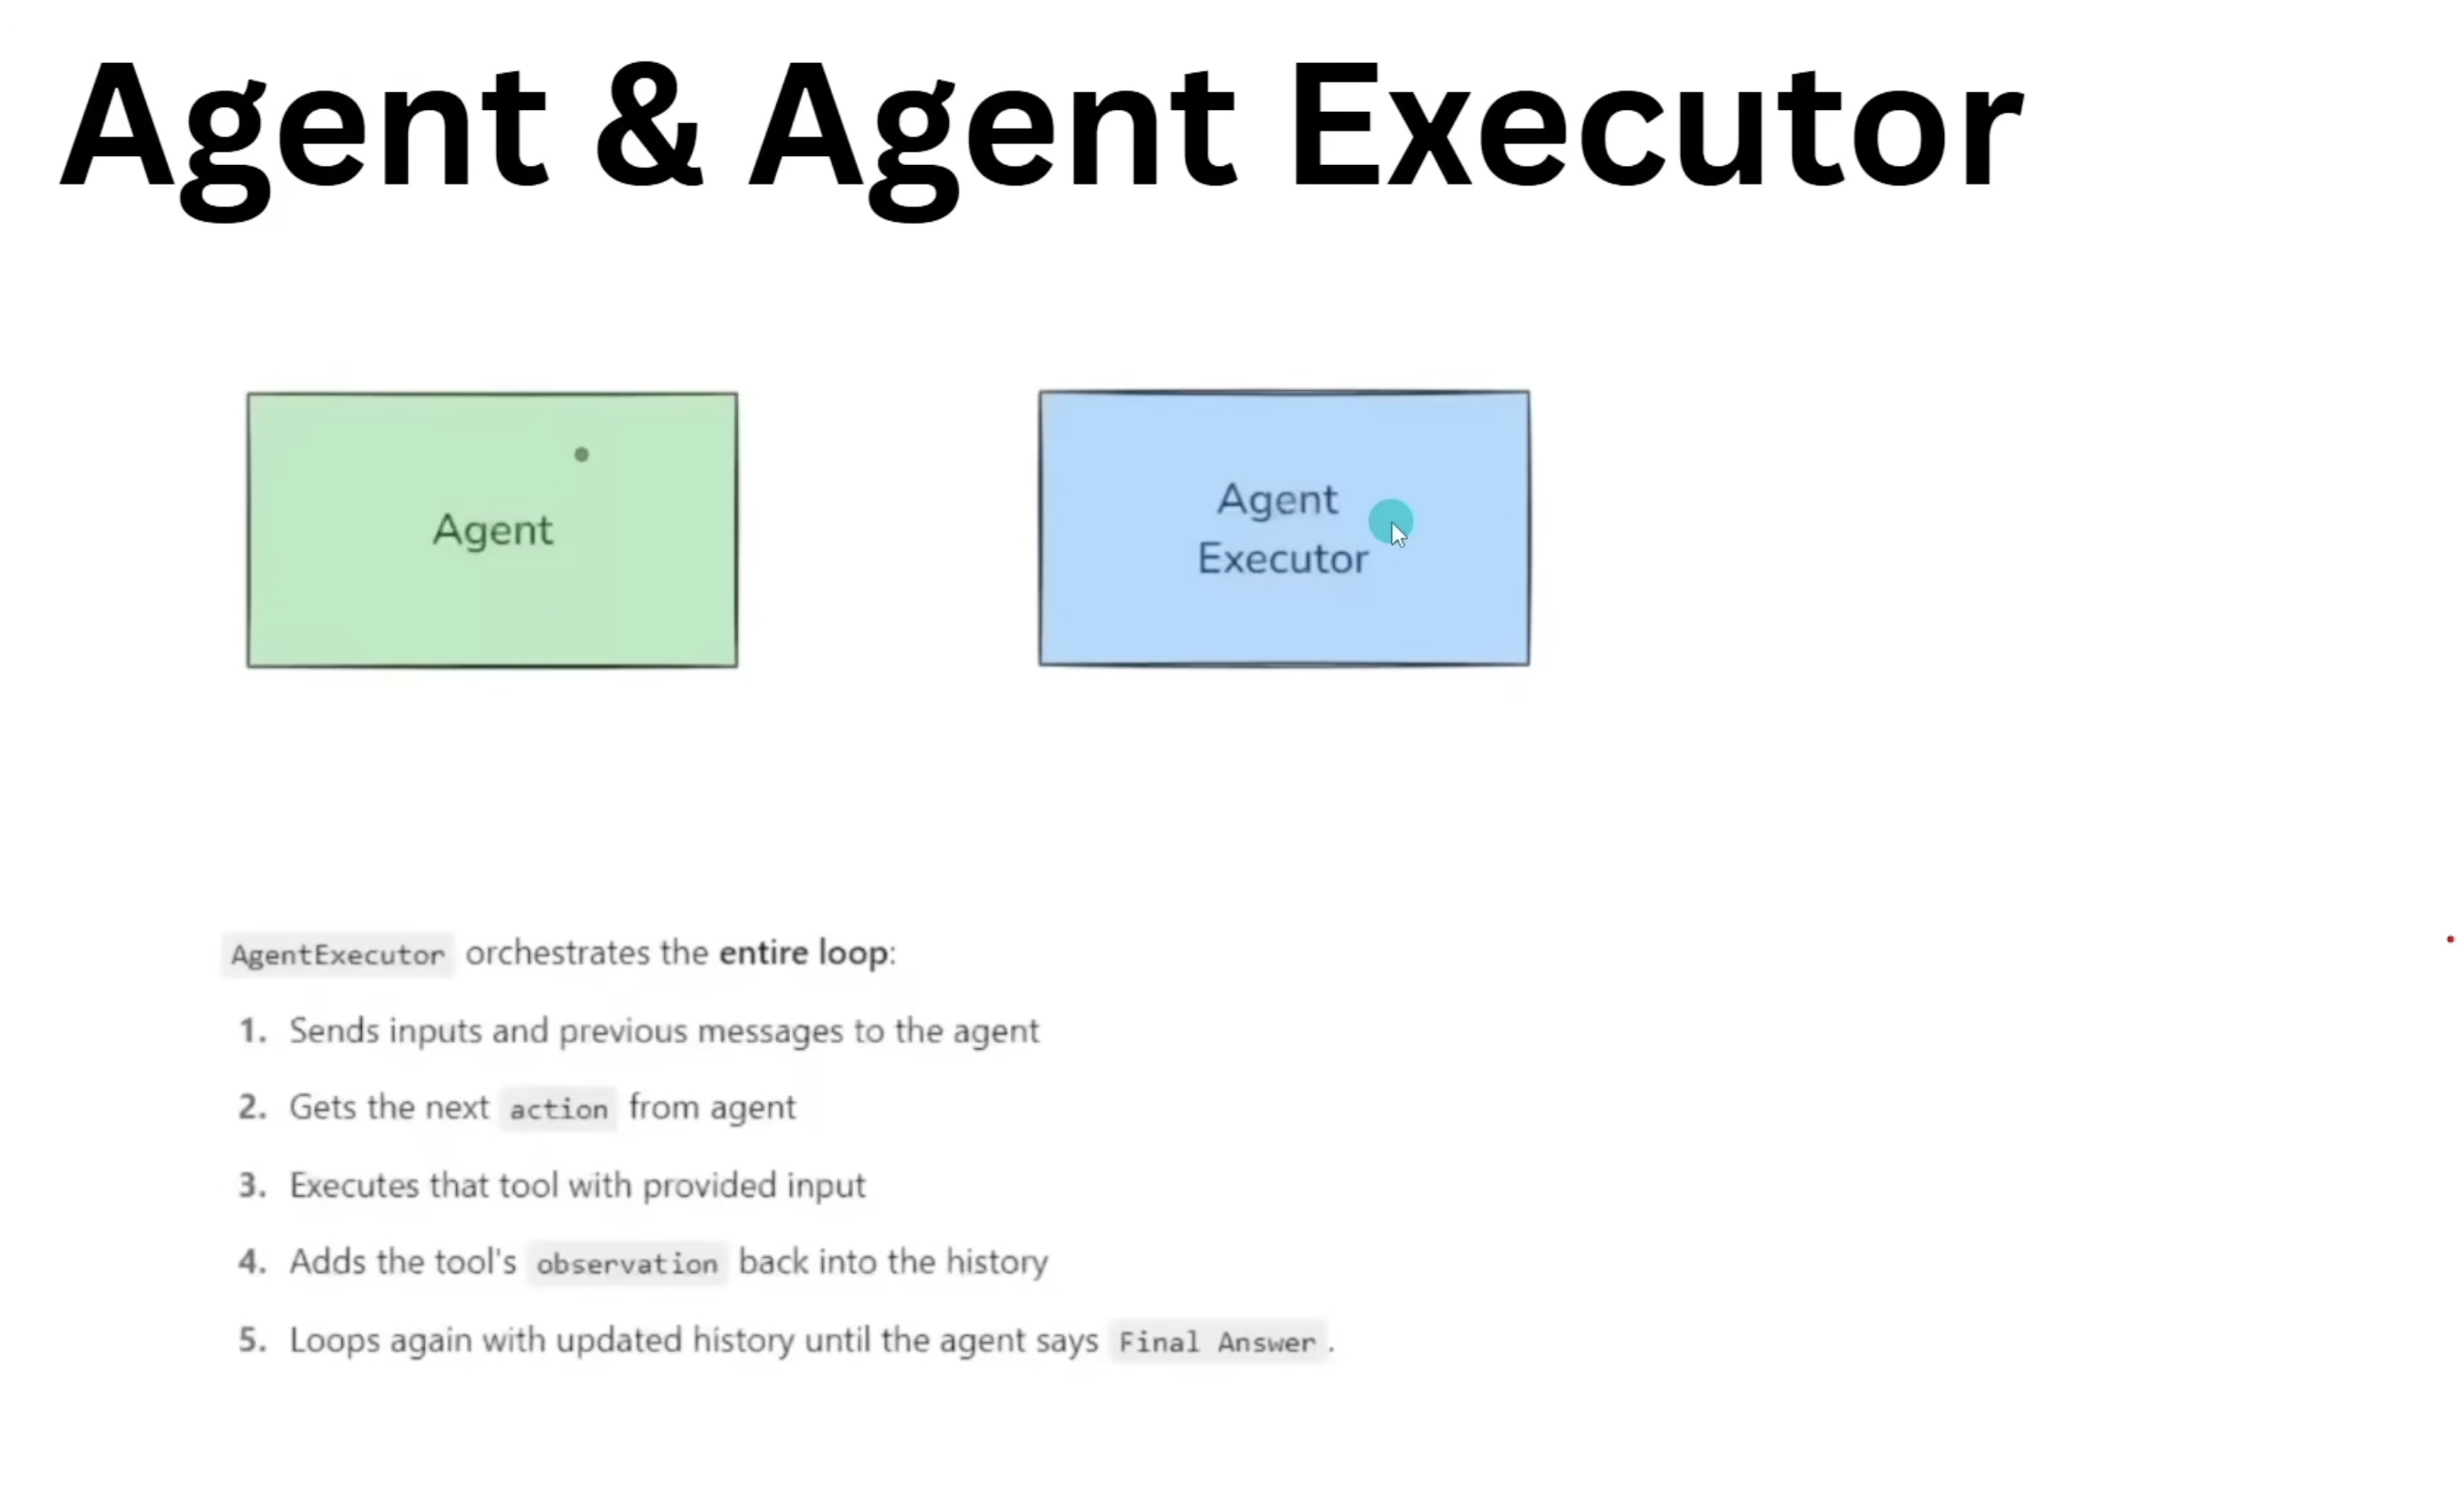

In [35]:
from IPython.display import Image, display

display(Image(filename="agent_and_agent_executor.png"))